In [1]:
# Cell 1: Import required library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt 
import seaborn as sns
from PIL import Image
from pathlib import Path

In [2]:
# Cell 2: load dataset & Setup
# Plot styling
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

# Paths
AUDIT_DIR = Path("../reports/audit")
RAW_DATA_DIR = Path("../data/raw/data1a")
FIGURES_DIR = Path("../reports/figures/eda")
FIGURES_DIR.mkdir(parents=True, exist_ok= True)

# Load inventory dataset
df = pd.read_csv(AUDIT_DIR / "dataset_inventory.csv")
print(f"Loaded {len(df)} images for EDA.")

Loaded 2300 images for EDA.


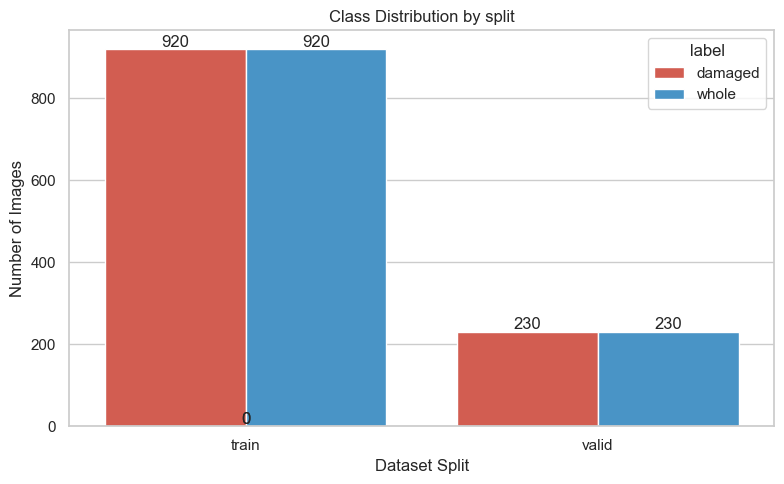

In [3]:
# Cell 3: Class Distribution
plt.figure(figsize=(8, 5))
ax = sns.countplot(data=df, x="split", hue="label", palette=["#e74c3c", "#3498db"])
plt.title("Class Distribution by split")
plt.ylabel("Number of Images")
plt.xlabel("Dataset Split")

# Add counts on top of bars
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center', xytext=(0, 5), textcoords='offset points')
plt.tight_layout()
plt.savefig(FIGURES_DIR / "class_distribution.png", dpi=150)
plt.show()

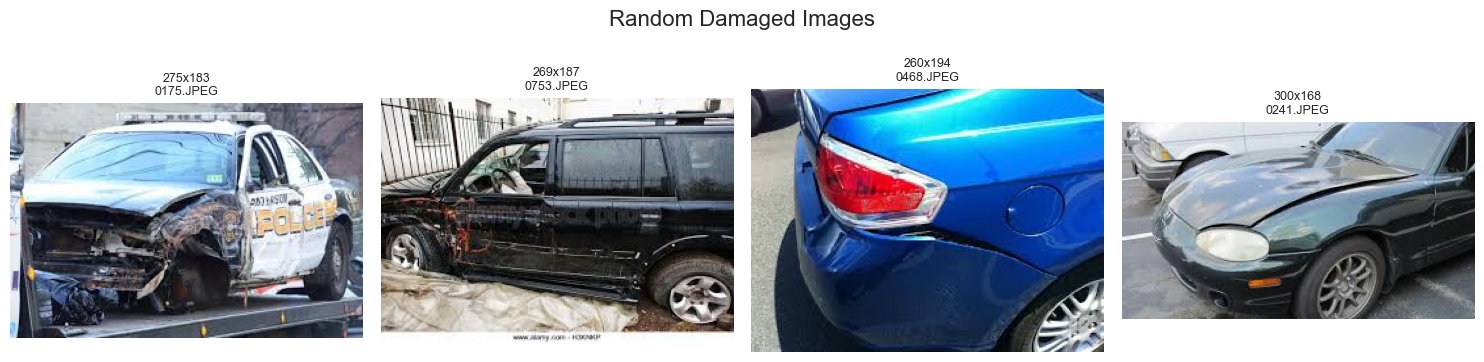

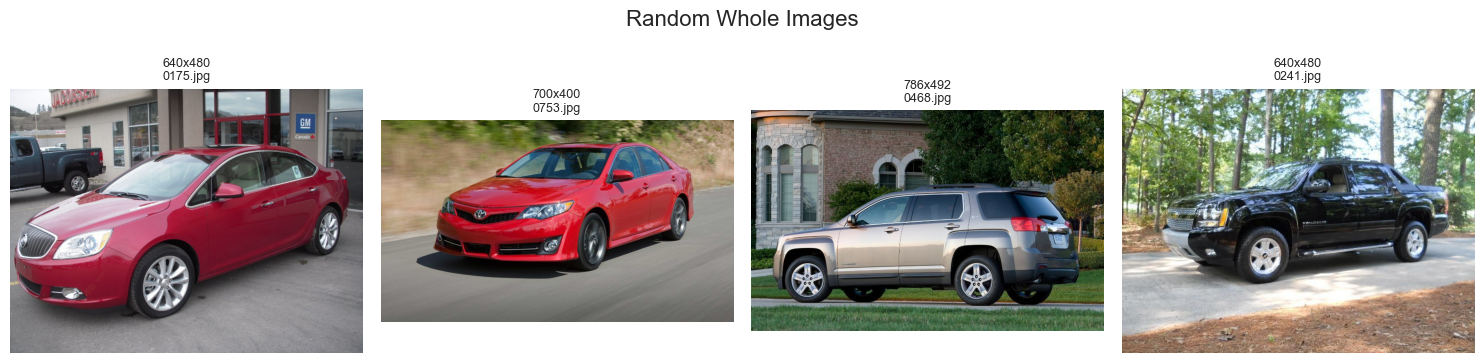

In [4]:
# Cell 4: Random Image Grid
def plot_image_grid(df_subset, title, num_images=4):
    fig, axes = plt.subplots(1, num_images, figsize = (15, 4))
    fig.suptitle(title, fontsize=16)

    # Sample random images
    samples = df_subset.sample(n = num_images, random_state = 42)

    for ax, (_, row) in zip(axes, samples.iterrows()):
        img_path = RAW_DATA_DIR / row["image_path"]
        img = Image.open(img_path)
        ax.imshow(img)
        ax.axis('off')
        ax.set_title(f"{row['width']}x{row['height']}\n{row['filename']}", fontsize=9)
    plt.tight_layout()
    plt.show()

# Plot Damaged
plot_image_grid(df[df["label"] == "damaged"], "Random Damaged Images")
# Plot Whole
plot_image_grid(df[df["label"] == "whole"], "Random Whole Images")

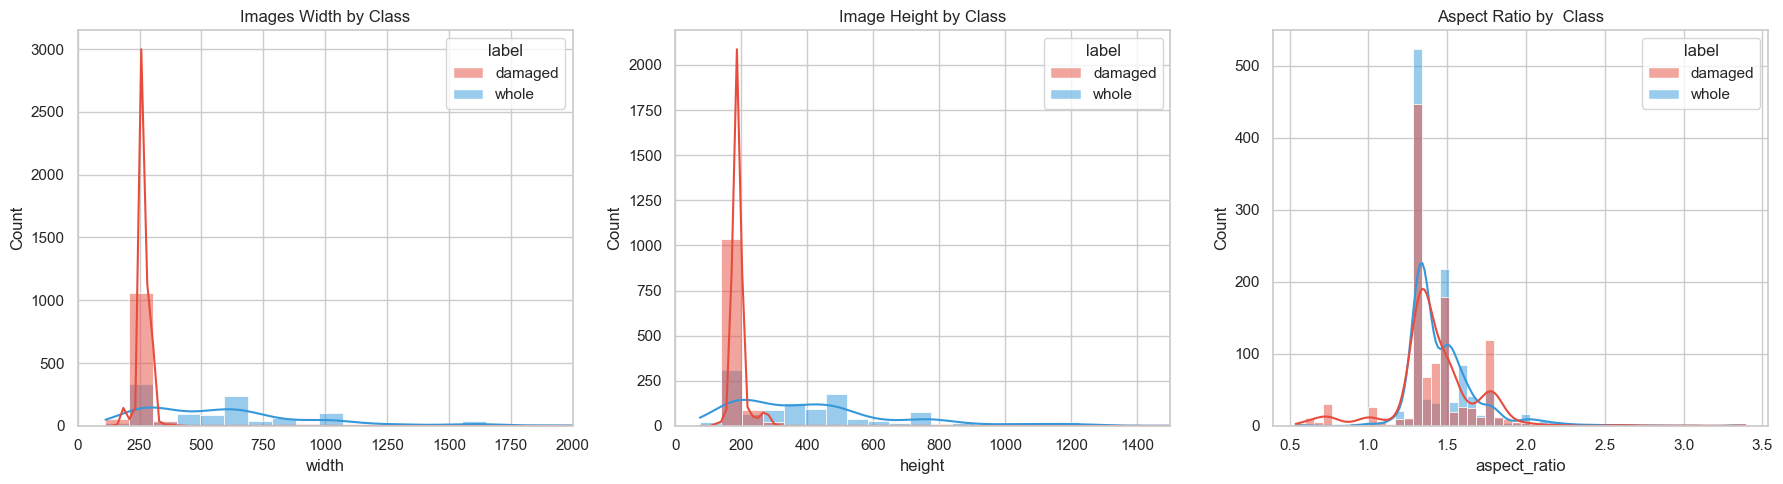

In [5]:
# Cell 5: Resolution and Aspect Ratio Distribution
fig, axes = plt.subplots(1, 3, figsize = (18, 5))

# Width Distribution
sns.histplot(data=df, x="width", hue="label", bins=50, ax=axes[0], palette=["#e74c3c", "#3498db"], kde=True)
axes[0].set_title("Images Width by Class")
axes[0].set_xlim(0, 2000)   # Limit to see the main cluster

# Height Distribution
sns.histplot(data=df, x="height", hue="label", bins=50, ax=axes[1], palette=["#e74c3c", "#3498db"], kde=True)
axes[1].set_title("Image Height by Class")
axes[1].set_xlim(0, 1500)

# Aspect Ratio Distribution
sns.histplot(data=df, x="aspect_ratio", hue="label", bins=50, ax=axes[2], palette=["#e74c3c", "#3498db"], kde=True)
axes[2].set_title("Aspect Ratio by  Class")

plt.tight_layout()
plt.savefig(FIGURES_DIR / "resolution_distribution.png", dpi=150)
plt.show()

Calculating brightness and blur metrics...


C:\Users\ASUS\AppData\Local\Temp\ipykernel_24100\3566416840.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_sample, x="label", y="brightness", ax=axes[0], palette=["#e74c3c", "#3498db"])
C:\Users\ASUS\AppData\Local\Temp\ipykernel_24100\3566416840.py:29: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_sample, x="label", y="blur_score", ax=axes[1], palette=["#e74c3c", "#3498db"])


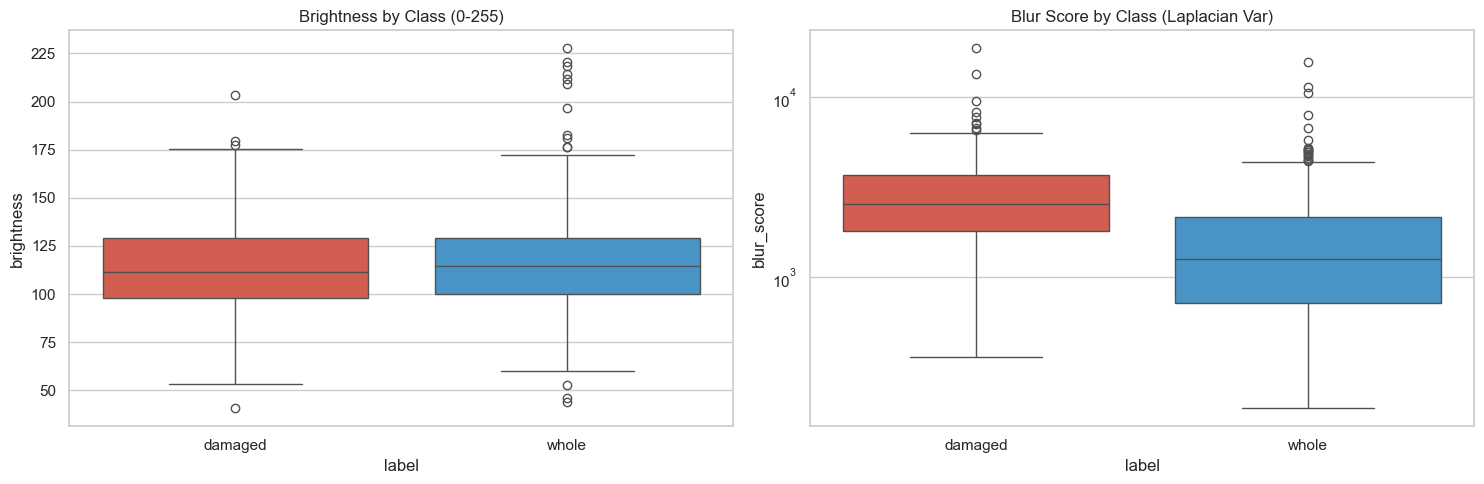

In [6]:
# Cell 6: Brightness and Blur Analysis
import cv2

def calculate_image_metrics(filepath):
    # Read in grayscale for brightness and blur
    img = cv2.imread(str(filepath), cv2.IMREAD_GRAYSCALE)
    if img is None:
        return None, None

    # Brightness: mean pixel intensity
    brightness = np.mean(img)

    # Blur: Variance of Laplacian (lower = more blurry)
    blur_score = cv2.Laplacian(img, cv2.CV_64F).var()
    return brightness, blur_score

print("Calculating brightness and blur metrics...")
# Apply to a sample of 500 images to save time
df_sample = df.sample(n=500, random_state=42).copy()
metrics = df_sample["image_path"].apply(lambda x: calculate_image_metrics(RAW_DATA_DIR / x))
df_sample[["brightness", "blur_score"]] = pd.DataFrame(metrics.tolist(), index=df_sample.index)


# Plot
fig, axes = plt.subplots(1, 2, figsize = (15, 5))
sns.boxplot(data=df_sample, x="label", y="brightness", ax=axes[0], palette=["#e74c3c", "#3498db"])
axes[0].set_title("Brightness by Class (0-255)")

sns.boxplot(data=df_sample, x="label", y="blur_score", ax=axes[1], palette=["#e74c3c", "#3498db"])
axes[1].set_yscale('log') # Log scale due to huge variance
axes[1].set_title("Blur Score by Class (Laplacian Var)")

plt.tight_layout()
plt.savefig(FIGURES_DIR / "brightness_blur.png", dpi=150)
plt.show()

Grayscale image found: ['training\\01-whole\\0058.jpg']


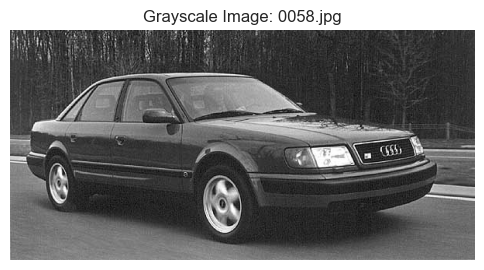

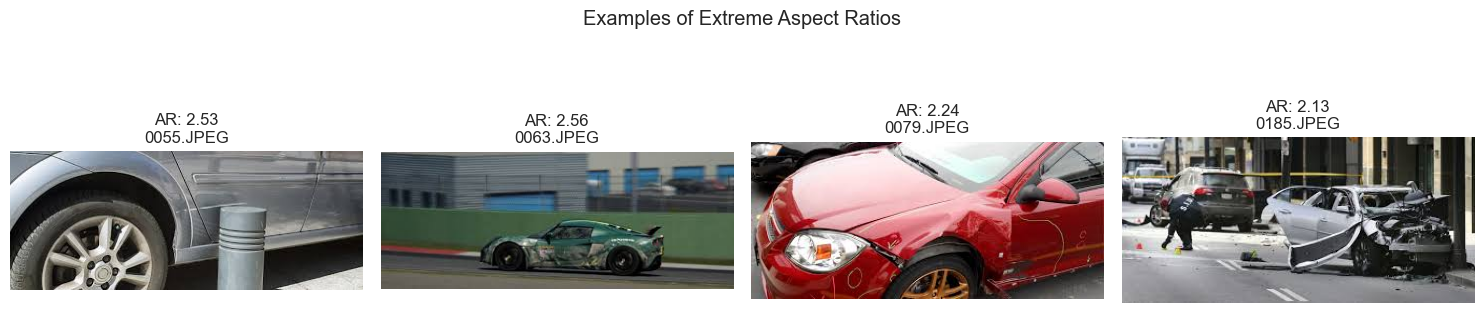

In [7]:
# Cell 7: Inspecting Anomalies
# 1. Grayscale image
gray_img = df[df["color_mode"] == "L"]
print(f"Grayscale image found: {gray_img['image_path'].values}")
img = Image.open(RAW_DATA_DIR / gray_img["image_path"].values[0])
plt.figure(figsize=(6, 6))
plt.imshow(img, cmap="gray")
plt.title(f"Grayscale Image: {gray_img['filename'].values[0]}")
plt.axis('off')
plt.savefig(FIGURES_DIR / "anomaly_grayscale.png", dpi=150)
plt.show()

# 2. Extreme aspect ratios
extreme = df[(df["aspect_ratio"] < 0.5) | (df["aspect_ratio"] > 2.0)]
fig, axes = plt.subplots(1, 4, figsize=(15, 4))
fig.suptitle("Examples of Extreme Aspect Ratios")
for ax, (_, row) in zip(axes, extreme.head(4).iterrows()):
    img = Image.open(RAW_DATA_DIR / row["image_path"])
    ax.imshow(img)
    ax.axis('off')
    ax.set_title(f"AR: {row['aspect_ratio']:.2f}\n{row['filename']}")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "anomaly_aspect_ratio.png", dpi=150)
plt.show()

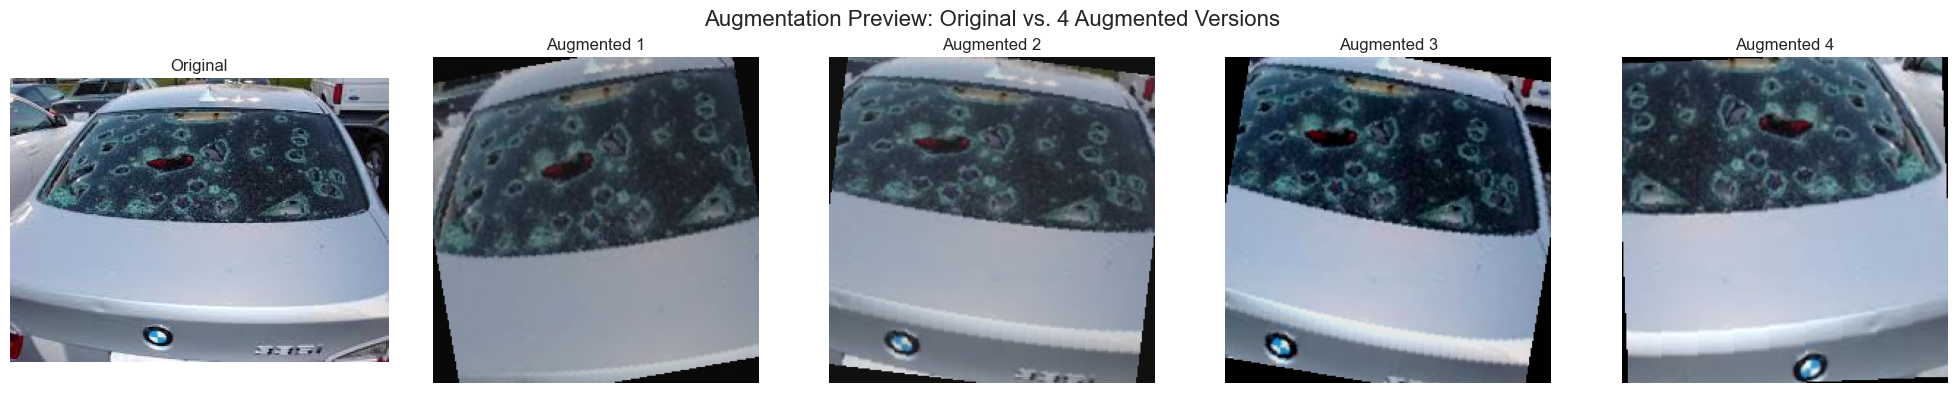

In [9]:
# Cell 8: Augmentation Preview
import torch
import torchvision.transforms as T
from torchvision.transforms import functional as F

# Define the "Advanced" augmentation pipeline we plan to use for training
train_transforms = T.Compose([
    T.Resize(256),                # Resize shortest side to 256
    T.RandomResizedCrop(224, scale=(0.6, 1.0)), # Crop and resize to 224x224
    T.RandomHorizontalFlip(p=0.5),
    T.RandomRotation(degrees=15),
    T.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    T.ToTensor(),
    T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# Select one damaged image to visualize
sample_path = df[df["label"] == "damaged"].iloc[10]["image_path"]
img = Image.open(RAW_DATA_DIR / sample_path).convert("RGB")

# Create a figure to show the original and 4 augmented versions
fig, axes = plt.subplots(1, 5, figsize=(20, 4))
fig.suptitle("Augmentation Preview: Original vs. 4 Augmented Versions", fontsize=16)

# Show Original
axes[0].imshow(img)
axes[0].set_title("Original")
axes[0].axis('off')

# Show 4 Augmented versions
for i in range(1, 5):
    # Apply transform
    aug_img = train_transforms(img)
    # Un-normalize for display
    aug_img = aug_img * torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1) + torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
    aug_img = aug_img.permute(1, 2, 0).numpy()
    aug_img = np.clip(aug_img, 0, 1) # Clip values to valid range for display
    
    axes[i].imshow(aug_img)
    axes[i].set_title(f"Augmented {i}")
    axes[i].axis('off')

plt.tight_layout()
plt.savefig(FIGURES_DIR / "augmentation_preview.png", dpi=150)
plt.show()

In [10]:
# Cell 9: Quantify the Shortcut
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
import warnings
warnings.filterwarnings('ignore') # Ignore convergence warnings for this test

# Ensure target is binary
y = (df["label"] == "damaged").astype(int)
cv = StratifiedKFold(5, shuffle=True, random_state=42)

# We will test a model that ONLY sees metadata, not pixels
feature_sets = {
    "width only": ["width"],
    "width+height+AR": ["width", "height", "aspect_ratio"],
}

print("Testing if image metadata alone can predict damage (0.5 = random):\n")
for name, cols in feature_sets.items():
    for mname, model in [("logreg", make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))),
                         ("tree", DecisionTreeClassifier(max_depth=3, random_state=42))]:
        acc = cross_val_score(model, df[cols], y, cv=cv, scoring="accuracy").mean()
        print(f"{name:20s} | {mname:6s} | Accuracy = {acc:.3f}")

Testing if image metadata alone can predict damage (0.5 = random):

width only           | logreg | Accuracy = 0.833
width only           | tree   | Accuracy = 0.843
width+height+AR      | logreg | Accuracy = 0.833
width+height+AR      | tree   | Accuracy = 0.849


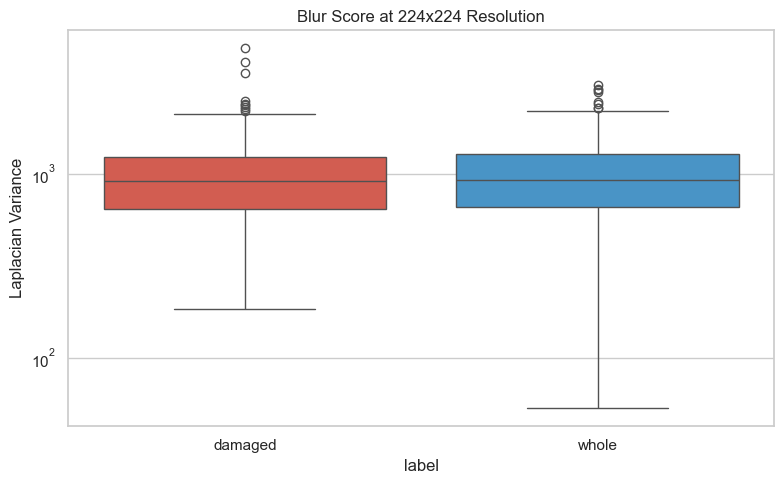

In [11]:
# Cell 10: Blur after Standard Resize
import cv2

def blur_224(path):
    try:
        # Resize to 224x224 exactly as the model will see it
        im = Image.open(path).convert("L").resize((224, 224), Image.BILINEAR)
        return cv2.Laplacian(np.array(im), cv2.CV_64F).var()
    except:
        return np.nan

# Apply to the sample we used earlier
df_sample["blur_224"] = df_sample["image_path"].apply(lambda x: blur_224(RAW_DATA_DIR / x))

plt.figure(figsize=(8, 5))
sns.boxplot(data=df_sample, x="label", y="blur_224", hue="label", legend=False, palette=["#e74c3c", "#3498db"])
plt.yscale('log')
plt.title("Blur Score at 224x224 Resolution")
plt.ylabel("Laplacian Variance")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "blur_after_resize.png", dpi=150)
plt.show()

## EDA Summary and Risks

**1. Class Distribution**
- Perfectly balanced: 50/50 split of Damaged and Whole across both train and validation.

**2. The "Shortcut Feature" Risk (CRITICAL)**
- Visual inspection confirms that "Damaged" images are predominantly web-scraped thumbnails (mean width ~266px).
- "Whole" images are high-resolution press/dealership photos (mean width ~631px).
- **Quantified Risk:** A metadata-only Decision Tree (using only Width, Height, and Aspect Ratio) achieves **84.9% accuracy**. This mathematically proves the dataset is heavily biased by image source and resolution, not just physical damage.
- **Action:** We must neutralize this cue in Notebook 03 by downscaling all images to a common size, using standard resizing (no aggressive cropping), and applying JPEG/blur augmentation to both classes.

**3. Augmentation Preview Results**
- Aggressive `RandomResizedCrop` (scale 0.6-1.0) cuts out severe damage (e.g., shattered windows). 
- **Action:** Revert to a standard aspect-preserving resize or letterboxing.

**4. Blur Analysis**
- Initial blur scores were confounded by resolution. At a standardized 224x224 resolution, the difference between classes is significantly reduced (medians align, and the distributions heavily overlap). 
- **Action:** No special blur-specific handling needed, just standard normalization.

**5. Dataset Limitations**
- Dataset represents a time-boxed "damaged or not" gate, not a production-ready damage detector.
- Validation numbers will be optimistic due to source differences. A source-controlled out-of-distribution test set is required in Notebook 05 to verify true generalization.
- As noted by the reviewer: Treat this as a time-boxed task. The core of the project is the YOLO detector (when we get to it). Write the shortcut finding in the README as a limitation and an interview talking point.